[![Open In Colab](https://img.shields.io/badge/Open_in-Colab-F9AB00?logo=googlecolab&logoColor=white)](https://colab.research.google.com/gitlab/ivanvladimir/maquinas_notebooks/blob/main/basic/common_interface_grammars.ipynb)

This notebook illustrates the grammars in the _maquinas_ library

In [1]:
# Load, or install and load the library
try:
    import maquinas
except ImportError:
    %pip install -q git+https://gitlab.com/ivanvladimir/maquinas
    import maquinas

# Load machines

In [2]:
from maquinas.io import load_cfg, load_rg

import ipywidgets as widgets

In [81]:
grammars=[]

grammars.append(load_cfg(
"""---
label: "RG: a*bc*"
description: a's follow by a 'b' and follow by c's (RB)
accepted: [b, ab, bc, abc, aabc, abcc, aaaaaaaaaabccccccccc]
rejected: [ε, bb, a, c, abbc, aabbc, abbcc, bac, aaaaaaaaaaaaaaaabccccccccccccb]
---
S → aS
S → bA 
A → cA
A → ε;
B->b"""))

grammars.append(load_cfg(
"""---
label: "CFG: aⁿbⁿ, n >1"
description: A number of a's followed by the same number of b's (CFG)
accepted: [  aabb, aaaaaaaabbbbbbbb]
rejected: [ε,ab,a, b, ba, aaabb, aabbbbb]
---
S-> ACB
C-> ACB
C -> AB
A -> a
B->b"""))

grammars.append(load_rg("""
---
label: "RG: números flotantes"
description: Números flotantes
accepted: [ 1, -1,+1, 10.23, -10.23, 10.23e45, 10.23e-45, -10.23e45, -10.23e-45]
rejected: [ε,e,e-4, 1ee4, 1e4-]
---
                        
S → +A;
A → 0A;
B → 0C;
C → 0C;
D → +E;
E → 0F;
F → 0F;
S → -A;
A → 1A;
B → 1C;
C → 1C;
D → -E;
E → 1F;
F → 1F;
S → A;
A → 2A;
B → 2C;
C → 2C;
D → E;
E → 2F;
F → 2F;
A → 3A;
B → 3C;
C → 3C;
E → 3F;
F → 3F;
A → 4A;
B → 4C;
C → 4C;
E → 4F;
F → 4F;
A → 5A;
B → 5C;
C → 5C;
E → 5F;
F → 5F;
A → 6A;
B → 6C;
C → 6C;
E → 6F;
F → 6F;
A → 7A;
B → 7C;
C → 7C;
E → 7F;
F → 7F;
A → 8A;
B → 8C;
C → 8C;
E → 8F;
F → 8F;
A → 9A;
B → 9C;
C → 9C;
E → 9F;
F → 9F;
A → .B;
C → eD;
F → ε;
A → B;
C → ε
"""))



## Select the grammar to explore

In [82]:
dropdown = widgets.Dropdown(
    options=[(g.metadata.extra()['label'],g) for g in grammars],
    description="Autómata:",
)
dropdown

Dropdown(description='Autómata:', options=(('RG: a*bc*', <maquinas.contextfree.cfg.ContextFreeGrammar object a…

In [83]:
grammar=dropdown.value

# Testing share api with grammars

## Prints elements of the machine

In [84]:
grammar.print_info()

Description : Números flotantes

In [85]:
grammar.print_long_info()

Description : Números flotantes
Accepted    : 1, -1, +1, 10.23, -10.23, 10.23e45, 10.23e-45, -10.23e45, -10.23e-45
Rejected    : ε, e, e-4, 1ee4, 1e4-
Label       : RG: números flotantes

In [86]:
grammar.print_summary()

No terminal : S, A, B, C, D, E, F
Terminals   : +, 0, -, 1, 2, 3, 4, 5, 6, 7, 8, 9, ., e
Start       : S
Productions :
 S → +A | -A | A
 A → 0A | 1A | 2A | 3A | 4A | 5A | 6A | 7A | 8A | 9A | .B | B
 B → 0C | 1C | 2C | 3C | 4C | 5C | 6C | 7C | 8C | 9C
 C → 0C | 1C | 2C | 3C | 4C | 5C | 6C | 7C | 8C | 9C | eD | ε
 D → +E | -E | E
 E → 0F | 1F | 2F | 3F | 4F | 5F | 6F | 7F | 8F | 9F
 F → 0F | 1F | 2F | 3F | 4F | 5F | 6F | 7F | 8F | 9F | ε

## Renders mathematical representation

In [87]:
grammar

In [88]:
print(grammar.latex())

\begin{array}{l}G = (V, \Sigma, P, S) \\ V = \{S, A, B, C, D, E, F\} \\ \Sigma = \{\text{+}, 0, \text{-}, 1, 2, 3, 4, 5, 6, 7, 8, 9, \text{.}, e\} \\ S = S\end{array}\qquad \begin{array}{rcl}S & \to & \text{+}A \mid \text{-}A \mid A \\ A & \to & 0A \mid 1A \mid 2A \mid 3A \mid 4A \mid 5A \mid 6A \mid 7A \mid 8A \mid 9A \mid \text{.}B \mid B \\ B & \to & 0C \mid 1C \mid 2C \mid 3C \mid 4C \mid 5C \mid 6C \mid 7C \mid 8C \mid 9C \\ C & \to & 0C \mid 1C \mid 2C \mid 3C \mid 4C \mid 5C \mid 6C \mid 7C \mid 8C \mid 9C \mid eD \mid \varepsilon \\ D & \to & \text{+}E \mid \text{-}E \mid E \\ E & \to & 0F \mid 1F \mid 2F \mid 3F \mid 4F \mid 5F \mid 6F \mid 7F \mid 8F \mid 9F \\ F & \to & 0F \mid 1F \mid 2F \mid 3F \mid 4F \mid 5F \mid 6F \mid 7F \mid 8F \mid 9F \mid \varepsilon \\\end{array}


Copy string and paste it in latex code, to text it here: https://latexeditor.lagrida.com/

## Parses a string

In [89]:
testing_string=grammar.metadata.accepted[0]
print("String to test:",testing_string)

String to test: 1


In [90]:
grammar.accepts(testing_string)

True

In [91]:
roots,chart,forest=grammar.parse(testing_string)
print(f'Con "{testing_string}" Se acepta?', "Sí" if len(roots)>0 else "No" )

Con "1" Se acepta? Sí


In [92]:
trees=list(grammar.extract_trees(forest))
for i,tree in enumerate(trees):
    print(f"Tree {i+1}:")
    print(grammar.derivation2str(tree))

Tree 1:
S
 ⇒ A
 ⇒ B
 ⇒ 1C
 ⇒ 1


In [93]:
print("Analysing string that should be accepted")
for t in grammar.metadata.accepted:
    print(f"  Does {t if len(t) > 0 else 'ε' } is accepted?", "✓" if grammar.accepts(t) else "𐄂" )

Analysing string that should be accepted
  Does 1 is accepted? ✓
  Does -1 is accepted? ✓
  Does +1 is accepted? ✓
  Does 10.23 is accepted? ✓
  Does -10.23 is accepted? ✓
  Does 10.23e45 is accepted? ✓
  Does 10.23e-45 is accepted? ✓
  Does -10.23e45 is accepted? ✓
  Does -10.23e-45 is accepted? ✓


In [94]:
print("Analysing string that should be rejected")
for t in grammar.metadata.rejected:
    print(f"  Does {t if len(t) > 0 else 'ε' } is accepted?", "✓" if grammar.accepts(t) else "𐄂" )

Analysing string that should be rejected
  Does ε is accepted? 𐄂
  Does e is accepted? 𐄂
  Does e-4 is accepted? 𐄂
  Does 1ee4 is accepted? 𐄂
  Does 1e4- is accepted? 𐄂


## Printing trees and forest

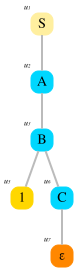

In [95]:
trees=list(grammar.extract_trees(forest))
grammar.draw_trees(trees,show_id=True)

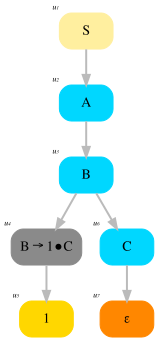

In [96]:
grammar.draw_forest(forest,show_id=True)

## Shows the parsing information

In [97]:
grammar.chart2table(testing_string)

## Creating an animation of parsing

In [ ]:
grammar.save_animation(testing_string, show=True)

In [ ]:
grammar.save_animation(grammar.metadata.rejected[0], show=True)